<table border=0 width="100%"><tr><td><p align="left"><img src="..\img\logo.png" align="left" width=300></p></td><td><font size=3><B>KNN for stock prediction (Haichao Zheng)</B></font></td></tr></table>

today's topic
- KNN
- A method for automatic stock trading combining technical analysis and nearest neighbor classification
- download data
- generate features
- create lables
- split dataset
- normalize input data
- train model
- make prediction on test data
- evaluate your model
- use pipeline
- develope strategy using KNN output
- optimize the investment strategy

# train_test_split and StandardScaler

In [4]:
import random

students = ["黄宇彬", "刘苗苗", "庞佳仪", "蒋依伶", "刘美言", "张栖瑜","许茂洋","刘艺婧"]  # 学生列表

# 我们如何写一个程序选择学生回答上节课的问题呢？
while True:
    winner = random.choice(students)
    print(winner)
    
    students.remove(winner)
    
    if len(students) == 7:
        break

刘苗苗


train_test_split and StandardScaler

In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Create a DataFrame with four features (columns) and 100 samples (rows)
data = pd.DataFrame({
    'feature1': np.random.randint(0, 100, size=100),
    'feature2': np.random.randint(0, 100, size=100),
    'feature3': np.random.randint(0, 100, size=100),
    'feature4': np.random.randint(0, 100, size=100),
#     'label':np.random.randint(0,2,100)
})

In [ ]:
data

# KNN（K-Nearest Neighbors）

# KNN（K-Nearest Neighbors）

## what is KNN

KNN（K-Nearest Neighbors）是一种基本的监督学习算法，用于分类和回归任务。KNN模型基于实例之间的相似性度量，通过对最近邻居的投票或平均值来进行预测。

在KNN模型中，训练数据集由特征向量和对应的标签组成。在进行预测时，模型会计算待预测样本与训练数据集中各个样本之间的距离，通常使用欧氏距离或曼哈顿距离等作为距离度量标准。

KNN模型的工作原理如下：

- 选择一个合适的K值，即要考虑的最近邻居的数量。
- 对于待预测样本，计算其与训练数据集中每个样本之间的距离。
- 根据距离的大小，选择最近的K个样本作为最近邻居。
- 对于分类任务，根据最近邻居的标签进行投票，将得票最多的类别作为预测结果。
- 对于回归任务，根据最近邻居的标签进行平均或加权平均，得到预测结果

- 欧氏距离 $d$ 为：
$$𝑑 = \sqrt{(𝑥₁−𝑥₂)² + (𝑦₁−𝑦₂)²}$$


其中，$x_1$、$y_1$ 表示第一个点的坐标，$x_2$、$y_2$ 表示第二个点的坐标。


- 曼哈顿距离 = |x2 - x1| + |y2 - y1|


在KNN模型中选择适当的距离度量方式是很重要的，因为它会影响模型的性能和结果。以下是一些常见的距离度量方式以及选择方法：

- 欧氏距离（Euclidean distance）：适用于连续型特征的度量，常用于大多数情况。欧式距离假设所有的特征对模型的贡献是平等的，并且在处理具有相同重要性的特征时通常有效。

- 曼哈顿距离（Manhattan distance）：适用于特征空间是离散的情况，或者在特征具有明显不同的度量单位时使用。

KNN 有什么特色？
- 简单且易于理解和实现。
- 对于少量训练样本和特征维度较低的问题表现较好。
- 对异常值敏感，因为预测结果受最近邻居的影响较大。
- 随着数据量的增加，计算距离的时间和内存消耗较大。
- 没有要学习的参数（没有显式的学习过程）

## which K is better for KNN
假设我们有以下三个训练样本数据：

- 训练样本1：特征向量 [1, 2]，标签为 "A"。
- 训练样本2：特征向量 [2, 3]，标签为 "B"。
- 训练样本3：特征向量 [4, 4]，标签为 "A"。  

请给出使用欧式距离，做KNN模型.

现在我们要预测一个新的测试样本，特征向量为 [3, 3]，我们将使用KNN模型来进行分类。

当k=1和k=3时，结果相同吗？给出计算步骤？

选择合适的K值对KNN模型的分类效果至关重要。K值的选择可以通过交叉验证、网格搜索或经验法则来确定。

不同大小的K值会对分类效果产生影响：

- 当K值较小（如K=1）时，模型更加敏感和容易受到噪声的影响。模型可能会对个别样本点的分类错误敏感，容易出现过拟合的情况。这意味着模型可能对训练数据中的噪声点作出过度反应，导致分类边界过于复杂，可能会出现局部性较强的分类结果。

- 当K值较大时，模型更加稳定和平滑。通过考虑更多的邻居样本，模型可以更好地捕捉数据的整体分布和结构。这可以降低噪声的影响，减少过拟合的风险。然而，当K值过大时，模型可能会丧失一些局部细节和敏感性，导致分类边界过于平滑，可能无法很好地适应训练数据中的局部特征。

因此，选择合适的K值要考虑数据集的特点、噪声水平以及模型的复杂度需求。一般而言，较小的K值适合简单的数据集和较少的噪声，而较大的K值适合复杂的数据集和较多的噪声。此外，还可以通过交叉验证等方法来评估不同K值下的模型性能，并选择在验证集上表现最佳的K值。

## train KNN with KNeighborsClassifier

In [6]:
from sklearn.neighbors import KNeighborsClassifier
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)


# 训练样本特征向量
X_train = [[1, 2], [2, 3], [4, 4]]
# 训练样本标签
y_train = ['A', 'B', 'A']

# 创建KNN模型并指定k值为1
# metric='manhattan'
# metric='euclidean'
knn = KNeighborsClassifier(n_neighbors=3, metric='euclidean')
# 使用训练数据拟合模型
knn.fit(X_train, y_train)

# 待预测的测试样本
X_test = [[3, 3]]
# 预测测试样本的标签
y_pred = knn.predict(X_test)

# 输出预测结果
print(y_pred)

['A']


## K Neighbors and their voting results

In [29]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

# 训练样本特征向量
X_train = [[1, 2], [2, 3], [4, 4],[5,5]]
# 训练样本标签
y_train = ['A', 'B', 'A','B']

# 创建KNN模型并指定k值为3
knn = KNeighborsClassifier(n_neighbors=3,metric='euclidean')
# 使用训练数据拟合模型
knn.fit(X_train, y_train)

# 待预测的测试样本
X_test = [[3, 3], [2, 3], [5, 5]]

knn.predict(X_test)

# # 遍历每个样本
for i, x in enumerate(X_test):
    # 获取测试样本的最近邻居的索引和距离
    print(f"sample:{x}")
    distance,index = knn.kneighbors([x])
    print(distance[0])
    print(index[0])
    for idx in index[0]:
        print(X_train[idx])
    print()
    
    

sample:[3, 3]
[1.         1.41421356 2.23606798]
[1 2 0]
[2, 3]
[4, 4]
[1, 2]

sample:[2, 3]
[0.         1.41421356 2.23606798]
[1 0 2]
[2, 3]
[1, 2]
[4, 4]

sample:[5, 5]
[0.         1.41421356 3.60555128]
[3 2 1]
[5, 5]
[4, 4]
[2, 3]



讨论 - 你相信KNN的输出吗？

## caculate voting consistency
- 最大类别的投票数占总的投票数的比例

In [30]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

# 训练样本特征向量
X_train = [[1, 2], [2, 3], [4, 4],[5,5]]
# 训练样本标签
y_train = ['A', 'B', 'A','B']

# 创建KNN模型并指定k值为3
knn = KNeighborsClassifier(n_neighbors=3)
# 使用训练数据拟合模型
knn.fit(X_train, y_train)

# 待预测的测试样本
X_test = [[3, 3], [2, 3], [5, 5]]

# 创建空的DataFrame
df = pd.DataFrame(columns=['样本', '类别A投票数', '类别B投票数', '投票一致性', '投票预测结果'])

# 遍历每个样本
for i, x in enumerate(X_test):
    # 获取测试样本的最近邻居的索引和距离
    distances, indices = knn.kneighbors([x])

    # 统计投票结果
    votes = {'A': 0, 'B': 0}
    for idx in indices[0]:
        label = y_train[idx]
        votes[label] += 1

    # 计算投票一致性
        total_count = sum(votes.values())
        max_label = max(votes, key=votes.get)
        consistency = votes[max_label] / total_count
    
    # 添加信息到DataFrame
    df.loc[i] = [x, votes['A'], votes['B'], consistency, max_label]

# 打印DataFrame
df

,样本,类别A投票数,类别B投票数,投票一致性,投票预测结果
0,"[3, 3]",2,1,0.666667,A
1,"[2, 3]",2,1,0.666667,A
2,"[5, 5]",1,2,0.666667,B


# A method for automatic stock trading combining technical analysis and nearest neighbor classification

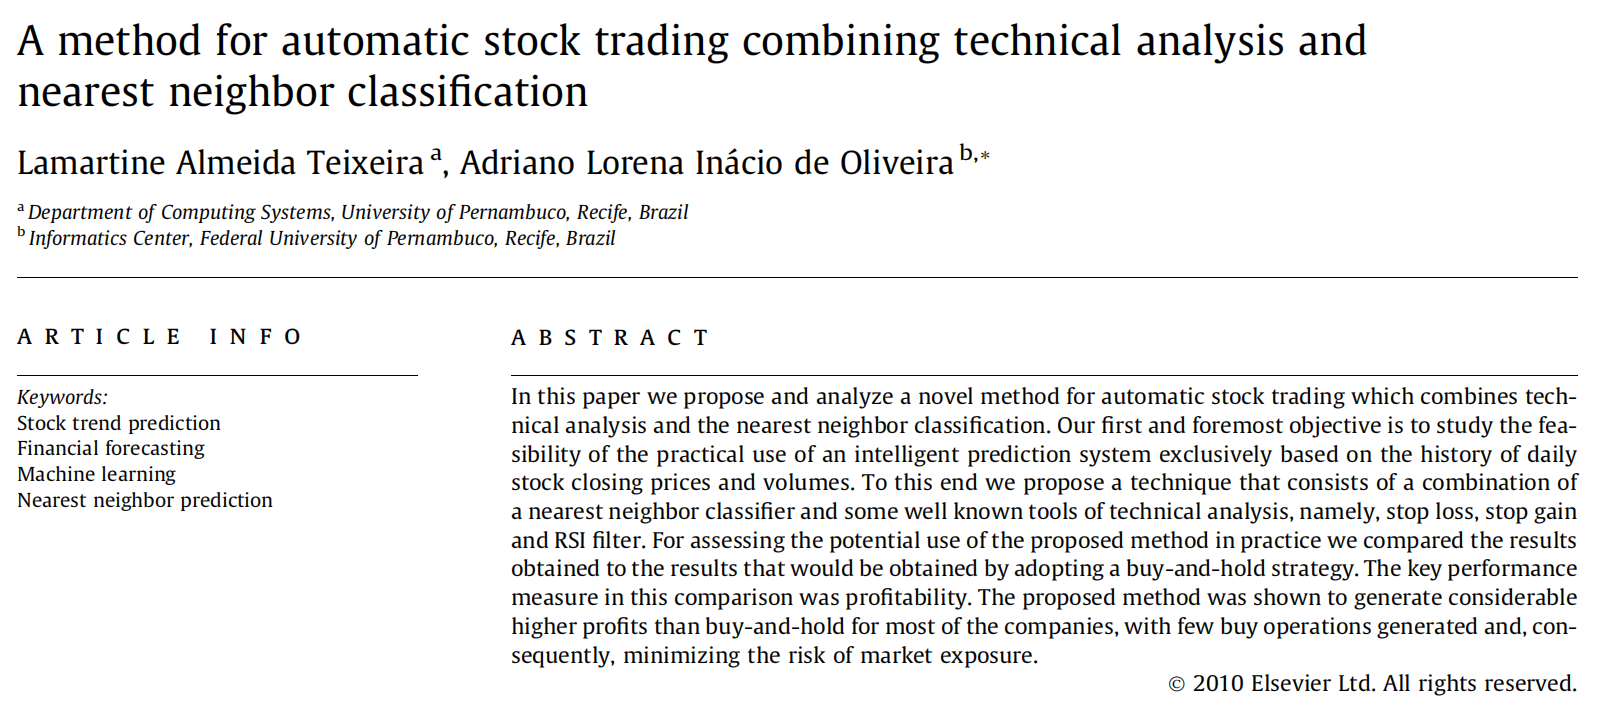

# download stock data

In [31]:
import tushare as ts
import pandas as pd
import numpy as np
token = 'aa6d7dba75bcd6eccd5bbda27e0cf6cf56c4759ec767990bdb041575'
ts.set_token(token)
pro = ts.pro_api()

start_date='19950101'
end_date='20230505'

index_daily = pro.index_daily(ts_code='000001.SH', start_date=start_date, end_date=end_date)
index_daily.trade_date = pd.DatetimeIndex(index_daily.trade_date)
index_daily.set_index("trade_date",inplace=True)
index_daily.sort_index(inplace=True)

In [32]:
index_daily.head()

,ts_code,close,open,high,low,pre_close,change,pct_chg,vol,amount
trade_date,,,,,,,,,,
1995-01-03,000001.SH,639.88,637.72,647.71,630.53,647.87,-7.99,-1.2333,234518.0,180693.264
1995-01-04,000001.SH,653.81,641.90,655.51,638.86,639.88,13.93,2.1770,422220.0,306923.352
1995-01-05,000001.SH,646.89,656.20,657.45,645.81,653.81,-6.92,-1.0584,430123.0,301532.788
1995-01-06,000001.SH,640.76,642.75,643.89,636.33,646.89,-6.13,-0.9476,487482.0,353757.725
1995-01-09,000001.SH,625.97,637.52,637.55,625.04,640.76,-14.79,-2.3082,509851.0,398519.515


In [33]:
index_daily.rename(columns={'vol': 'volume'}, inplace=True)
index_daily["date"] = index_daily.index
index_daily = index_daily[["date","open","high","low","close","volume","change","pct_chg","amount"]]

In [34]:
index_daily.head()

,date,open,high,low,close,volume,change,pct_chg,amount
trade_date,,,,,,,,,
1995-01-03,1995-01-03,637.72,647.71,630.53,639.88,234518.0,-7.99,-1.2333,180693.264
1995-01-04,1995-01-04,641.90,655.51,638.86,653.81,422220.0,13.93,2.1770,306923.352
1995-01-05,1995-01-05,656.20,657.45,645.81,646.89,430123.0,-6.92,-1.0584,301532.788
1995-01-06,1995-01-06,642.75,643.89,636.33,640.76,487482.0,-6.13,-0.9476,353757.725
1995-01-09,1995-01-09,637.52,637.55,625.04,625.97,509851.0,-14.79,-2.3082,398519.515


# generate some features for the trainning dataset

https://twopirllc.github.io/pandas-ta/

In [ ]:
# !pip install pandas_ta

In [36]:
import pandas_ta as ta

In [37]:
aroon = ta.aroon(index_daily['high'], index_daily['low'], length=10)
index_daily = pd.concat([index_daily,aroon],axis=1)

In [38]:
kd = ta.stoch(index_daily['high'], index_daily['low'], index_daily['close'])[['STOCHk_14_3_3', 'STOCHd_14_3_3']]
index_daily = pd.concat([index_daily,kd],axis=1)

In [39]:
adx = ta.adx(index_daily['high'], index_daily['low'], index_daily['close'])  # 平均趋向指标（Average Directional Index）
index_daily = pd.concat([index_daily,adx],axis=1)

In [40]:
kst = ta.kst(index_daily['close'])
index_daily = pd.concat([index_daily,kst],axis=1)

In [41]:
index_daily["nvi"] = ta.nvi(index_daily['close'], index_daily['volume'])
index_daily["pvi"] = ta.pvi(index_daily['close'], index_daily['volume'])

In [42]:
tsi = ta.tsi(index_daily['close'])
index_daily = pd.concat([index_daily,tsi],axis=1)

In [43]:
index_daily["ad"] = ta.ad(index_daily['high'], index_daily['low'], index_daily['close'], index_daily['volume']).diff()  # 钱流指标（Chaikin Money Flow）

In [44]:
index_daily['atr_14'] = ta.atr(index_daily['high'], index_daily['low'], index_daily['close'], length=14)

In [45]:
macd = ta.macd(index_daily['close'])[['MACD_12_26_9', 'MACDh_12_26_9', 'MACDs_12_26_9']]
index_daily = pd.concat([index_daily,macd],axis=1)

In [46]:
index_daily['srsi'] = ta.rsi(index_daily['close'], length=14, scalar=100, drift=1)

In [47]:
index_daily['momentum'] = ta.mom(index_daily['close'], length=10)

In [48]:
index_daily['rvi'] = ta.rvi(index_daily['close'], index_daily['high'], index_daily['low'], length=10)

In [49]:
index_daily['sma_20'] = ta.sma(index_daily['close'], length=20)  # 20日简单移动平均线
index_daily['sma_5'] = ta.sma(index_daily['close'], length=5)  # 5日简单移动平均线

index_daily['rsi'] = ta.rsi(index_daily['close']) # RSI

In [50]:
index_daily['std_20'] = index_daily.close.rolling(window=20).std()  # 计算标准差
index_daily['Bollinger_Upper'] = index_daily['sma_20'] + 2 * index_daily['std_20']    # 计算上轨
index_daily['Bollinger_Lower'] = index_daily['sma_20'] - 2 * index_daily['std_20']    # 计算下轨
index_daily["bandwidth"] = index_daily['Bollinger_Upper'] -  index_daily['Bollinger_Lower'] 

In [51]:
index_daily['obv'] = ta.obv(index_daily['close'], index_daily['volume']) #额度指标（OBV）
index_daily['obv_diff_lastday'] = index_daily['obv'] - index_daily['obv'].shift(1) # 额度指标（OBV）之差

# create labels for train data

In [52]:
index_daily["up_down_nextday"] = (index_daily.change > 0).astype(int)
index_daily["up_down_nextday"] = index_daily["up_down_nextday"].shift(-1) # 为什么要shift(-1)

In [53]:
# 请给出一个计算5日后的收盘价涨跌标签
# r = ((index_daily.close.shift(-5) - index_daily.close)>0).astype(int)
# index_daily["up_down_next_5_days"] = r
# index_daily["up_down_next_5_days"] = index_daily["up_down_next_5_days"].shift(-1)

# split dataset as two parts

我们可以使用Scikit-learn将数据集划分为训练集和测试集，可以使用train_test_split函数。
from sklearn.model_selection import train_test_split

- 假设你的特征矩阵为X，目标变量为y
X = dataset.drop(columns=['target'])  # 替换成你的特征矩阵
y = dataset['target']  # 替换成你的目标变量

- 划分为训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

但是对于时间序列数据，我们不能随机划分，要保留日期的先后顺序。

In [ ]:
index_daily.columns

In [54]:
features = ['pct_chg','AROOND_10', 'AROONU_10', 'AROONOSC_10', 'ADX_14', 'DMP_14',
       'DMN_14', 'KST_10_15_20_30_10_10_10_15', 'KSTs_9', 'nvi', 'pvi',
       'TSI_13_25_13', 'TSIs_13_25_13', 'ad', 'atr_14', 'MACD_12_26_9',
       'MACDh_12_26_9', 'MACDs_12_26_9', 'srsi', 'momentum', 'rvi','rsi', 'std_20', 
            'bandwidth', 'obv', 'obv_diff_lastday']

target = ["up_down_nextday"]

In [55]:
index_train = index_daily["2001":"2015"].copy() # train model
index_train.dropna(inplace=True) # 由于特征生成时引入一些空值，这里删除具有空值的数据
index_test = index_daily["2016":"20201231"].copy() # evaluate model

# index_test = index_daily["2021":"20230501"].copy() # evaluate model

In [56]:
# 生成模型训练使用的数据集
X_train, X_test, y_train, y_test = index_train[features],index_test[features], index_train[target],index_test[target]

# 获取用于交易测试的数据集
# X_trading = index_for_trading[features]

In [57]:
X_train.shape, y_train.shape

((3632, 26), (3632, 1))

In [58]:
X_test.shape, y_test.shape

((1218, 26), (1218, 1))

# normalized features

K最近邻算法（KNN）是一种基于样本之间距离的分类算法。对于KNN模型，数据的尺度和范围可以对距离计算产生重要影响。因此，对数据进行标准化预处理在KNN模型中是有意义的，有以下几个原因：

- 特征尺度的不同：如果特征具有不同的尺度或范围，那么具有较大值范围的特征可能会对距离计算产生更大的影响。例如，如果一个特征的值范围远大于其他特征，那么该特征对距离的贡献可能会占主导地位，导致其他特征的影响被忽略。通过标准化，可以将特征缩放到相似的尺度，避免尺度差异对距离计算的影响。

- 异常值的影响：异常值可能会对距离计算产生较大的影响，使得模型对异常值敏感。通过标准化，可以将数据转化为以均值为中心，方差为单位的分布，从而减小异常值对距离计算的影响。


总之，对数据进行标准化预处理可以确保不同特征具有相似的尺度和范围，减小尺度差异和异常值对距离计算的影响，提高模型的鲁棒性和收敛速度。这样，KNN模型能更准确地基于样本之间的距离进行分类或回归预测。

一定要使用训练集的信息（均值、标准差等）来标准化测试集的输入特征数据

In [59]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [60]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_train_scaled.shape

(3632, 26)

# train model

In [61]:
from sklearn.neighbors import KNeighborsClassifier

In [62]:
# 将目标变量转换为一维数组
if isinstance(y_train, pd.DataFrame):
    y_train = y_train.values.ravel()

In [63]:
isinstance(y_train, pd.DataFrame)

False

search for a better hyper-parameters

In [64]:
from sklearn.model_selection import GridSearchCV

import warnings
warnings.filterwarnings("ignore", message="the default value of `keepdims`")


param_grid = {'n_neighbors': [9, 11,21,31,41,51,61,61,71,81,91,101,111,121,131]}
# 创建KNN分类器实例
knn = KNeighborsClassifier()

# 创建GridSearchCV实例
grid_search = GridSearchCV(knn, param_grid, cv=5)

# 执行网格搜索
grid_search.fit(X_train_scaled, y_train)

# 输出最优的K值和对应的评分
print("最优的K值:", grid_search.best_params_['n_neighbors'])
print("最优的评分:", grid_search.best_score_)

最优的K值: 121
最优的评分: 0.5302765052046032


<img src="../img/cross_validation.jpg" align='left' height="300" width="500"/>

In [65]:
# 创建KNN模型并在训练数据上训练模型
knn = KNeighborsClassifier(n_neighbors=121)
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier(n_neighbors=121)

# make prediction on the test dataset

In [66]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # 忽略 FutureWarning

# 对测试数据进行相同的标准化处理
X_test_scaled = scaler.transform(X_test)

# 在测试数据上进行预测
y_pred = knn.predict(X_test_scaled)

# evaluate the model performance

回归模型和分类模型有不同的评估指标，回归模型我们可以使用均方误差$\frac {1}{m} \sum_{i=1}^m({f(x_i)-y_i})^2$。

对于二分类问题，我们可以根据其真实类别与模型预测类别的组合划分为真正例（true positive）（例如负面口碑、违约贷款）、真反例(true negative)、假正例（false postive）、假反例（false negative）四种情形（李航 2012）。分类的混淆矩阵如下表所示：
<table border="1">
<tr>
<td></td>
<td>正例（预测结果）</td>
<td>反例（预测结果）</td>
</tr>
<tr>
<td>正例（真实情况）</td>
<td>TP（true positive）</td>
<td>FN（false negative）</td>
</tr>
<tr>
<td>反例（真实情况）</td>
<td>FP（false positive）</td>
<td>TN（true negative）</td>
</tr>
</table>

对于分类模型，我们关心预测的准确率（accuracy）、查全率（recall）、查准率（precision）。准确率指正确预测的样本数占样本数的比例。假设测试集样本总数为$m$，那么正确率（accuracy）$$Accuracy=\frac {TP+TN}{m}$$
查全率（recall）指正例（我们关心的样本）中有多少比例被预测出来了，$$Recall = \frac {TP}{TP+FN}$$
查准率（precision）指预测出来的正例有多少比例是用户感兴趣的真正的正例，$$Precision = \frac {TP}{TP+FP}$$

查全率和查准率是一对矛盾的度量，一般来说，查准率高，查全率往往偏低；查全率高时，查准率往往偏低。这在信息检索时比较好理解，例如我们通过搜索引擎查询信息，如果希望查全率高，那么就会把阈值设置严格，这样查全率就低。如果希望查全率高，那么很多不想要的也可能被查询出来，因此查准率降低了。

**不同场景我们对查全率和查准率的重视程度不同**。

如果我们认为查全率和查准率同等重要，即二者的权重相同，那么我们可以使用F1度量指标来评估分类模型：$$F1 = \frac {2*Recall*Precision}{Recall + Precision}$$

In [67]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [68]:
y_pred

array([1., 1., 1., ..., 0., 1., 1.])

In [69]:
# 计算准确率
accuracy = accuracy_score(y_test.values, y_pred)
print("准确率:", accuracy)

# 计算精确率
precision = precision_score(y_test, y_pred, average='weighted')
print("精确率:", precision)

# 计算召回率
recall = recall_score(y_test, y_pred, average='weighted')
print("召回率:", recall)

# 计算F1-score
f1 = f1_score(y_test, y_pred, average='weighted')
print("F1-score:", f1)

准确率: 0.5254515599343186
精确率: 0.5220009759893433
召回率: 0.5254515599343186
F1-score: 0.5219942015016081


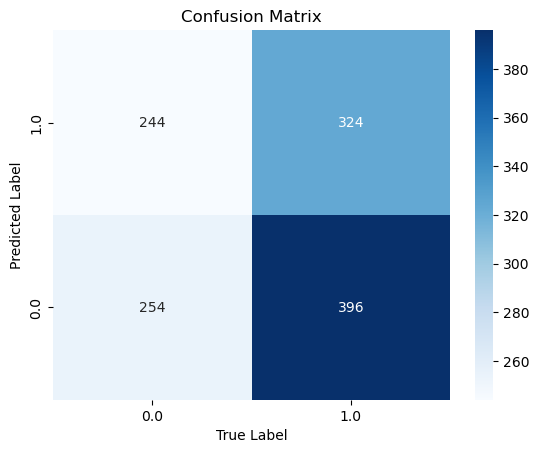

In [70]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

# 计算混淆矩阵
cm = confusion_matrix(y_test, y_pred)

# 创建类别标签
labels = sorted(y_test.iloc[:, 0].unique())

# 创建热力图
sns.heatmap(cm, annot=True, cmap='Blues', fmt='d', xticklabels=labels, yticklabels=labels[::-1])

# 设置图形标题和坐标轴标签
plt.title('Confusion Matrix')
plt.xlabel('True Label')
plt.ylabel('Predicted Label')

# 显示图形
plt.show()

In [ ]:
X_test.index

# use pipeline to combine data processing and model training

Pipeline是scikit-learn库中的一个工具，用于将多个数据处理步骤和机器学习模型组合成一个整体流水线（pipeline）。每个步骤可以是数据预处理、特征提取、特征选择、模型训练等操作。

使用Pipeline有以下几个好处：

- 代码简洁清晰：Pipeline将多个步骤整合在一起，使代码更加简洁和可读。可以通过一次性定义整个流水线，避免在不同步骤之间来回切换和处理数据。

- 防止数据泄漏：在交叉验证过程中，每个训练集和验证集的数据都会在每个步骤中进行处理。使用Pipeline可以确保每个步骤中的数据处理方式一致，避免了数据泄漏问题。

In [72]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# 创建Pipeline对象，定义每个步骤的名称和操作
pipeline = Pipeline([
    ('scaler', StandardScaler()),  # 数据标准化步骤
    ('knn', KNeighborsClassifier(n_neighbors=121))  # KNN模型步骤
])

# 训练模型
pipeline.fit(X_train_scaled, y_train)

# 进行预测
y_pred = pipeline.predict(X_test_scaled)

In [73]:
# 计算准确率
accuracy = accuracy_score(y_test, y_pred)
print("准确率:", accuracy)

# 计算精确率
precision = precision_score(y_test, y_pred, average='weighted')
print("精确率:", precision)

# 计算召回率
recall = recall_score(y_test, y_pred, average='weighted')
print("召回率:", recall)

# 计算F1-score
f1 = f1_score(y_test, y_pred, average='weighted')
print("F1-score:", f1)

准确率: 0.5254515599343186
精确率: 0.5220009759893433
召回率: 0.5254515599343186
F1-score: 0.5219942015016081


# develop investment strategy based on KNN prediction

In [ ]:
y_pred = pipeline.predict(X_test_scaled)

df = pd.DataFrame()
df.index = X_test.index
df["y_test"] = y_test
df["y_pred"] = y_pred


# 根据条件生成交易信号
buy_condition = (df['y_pred'] == 1)
sell_condition = (df['y_pred'] == 0)

df.loc[buy_condition, 'signals'] = 1  # 生成购买信号1
# df.loc[sell_condition, 'signals'] = -1  # 生成卖出信号-1

df['position']=df['signals'].shift(1)
df['position'].fillna(0,inplace=True)
# df['position'] = df['position'].replace(-1, 0) # we do not use short 


df["close"] = index_test.close

df["return"] = df["close"].apply(np.log).diff()
df["strategy"] = df["position"] * df["return"]

trade_cost = 0.001
if trade_cost>0:
    df["trade_cost"] = 0
    df.loc[~df.signals.isna(),["trade_cost"]] = trade_cost
    df["strategy_with_tradecost"] = df["strategy"] - df["trade_cost"]

df[["return","strategy"]].cumsum().apply(np.exp).plot(figsize=(10,6))

print(df.position.value_counts())

## evaluate the KNN strategy

In [ ]:
## 
# 定义函数：计算最大回撤
def max_drawdown(capital):
    """
    该函数计算最大回撤：财富的最大损失幅度
    capital：表示财富值，如果你已经计算出对数收益率为T，可以T.cumsum().apply(np.exp)计算累计财富值
    """
    max_capital = np.zeros(len(capital))
    drawdown = np.zeros(len(capital))
    max_drawdown = 0.0
    
    for i in range(1, len(capital)):
        max_capital[i] = max(max_capital[i-1], capital[i])
        drawdown[i] = (max_capital[i] - capital[i]) / max_capital[i]
        max_drawdown = max(max_drawdown, drawdown[i])
        
    return max_drawdown


# 设置函数：计算净值曲线的绩效指标
def get_Performance_analysis(T,year_day = 252):
    '''
    输入：T表示每日的收益率序列，每年的期数,我们默认是250个交易日
    
    输出：绩效指标
    '''

    # 计算年化收益率
    year_ret_mean = np.exp(T.dropna().mean() * year_day) - 1
    year_ret_mean = round(year_ret_mean*100,2)
    
    
    # 计算年化波动率
    volitiy = T.dropna().std()*np.sqrt(year_day)
    volitiy = round(volitiy*100,2)
    
    #计算夏普，无风险收益率记2%
    Sharpe = (year_ret_mean - 2)/volitiy
    Sharpe = round(Sharpe,2)

    # 计算最大回撤
    downlow = max_drawdown(T.cumsum().apply(np.exp))
    downlow = round(downlow*100,2)
    
    # 输出
    return [year_ret_mean,downlow,Sharpe,volitiy]

In [ ]:
# 绩效指标
columns = ['年化收益率 % ','最大回撤 % ','夏普比率','年化波动率']
# 创建表格
finace_ret_df = pd.DataFrame(columns = columns)
# 调用投资绩效分析函数
finace_ret_df.loc['strategy'] = get_Performance_analysis(T = df["strategy"]) 
finace_ret_df.loc['market'] = get_Performance_analysis(T = df["return"]) 
finace_ret_df

# optimize the investment strategy
## considering voting consistency

In [ ]:
# # 最大类别的投票数占总的投票数的比例

# import pandas as pd
# from sklearn.neighbors import KNeighborsClassifier

# # 训练样本特征向量
# X_train = [[1, 2], [2, 3], [4, 4],[5,5]]
# # 训练样本标签
# y_train = ['A', 'B', 'A','B']

# # 创建KNN模型并指定k值为3
# knn = KNeighborsClassifier(n_neighbors=3)
# # 使用训练数据拟合模型
# knn.fit(X_train, y_train)

# # 待预测的测试样本
# X_test = [[3, 3], [2, 3], [5, 5]]

# # 创建空的DataFrame
# df = pd.DataFrame(columns=['样本', '类别A投票数', '类别B投票数', '投票一致性', '投票预测结果'])

# # 遍历每个样本
# for i, x in enumerate(X_test):
#     # 获取测试样本的最近邻居的索引和距离
#     distances, indices = knn.kneighbors([x])

#     # 统计投票结果
#     votes = {'A': 0, 'B': 0}
#     for idx in indices[0]:
#         label = y_train[idx]
#         votes[label] += 1

#     # 计算投票一致性
#     total_count = sum(votes.values())
#     max_label = max(votes, key=votes.get)
#     consistency = votes[max_label] / total_count

#     # 添加信息到DataFrame
#     df.loc[i] = [x, votes['A'], votes['B'], consistency, max_label]

# # 打印DataFrame
# df

In [ ]:
y_pred = pipeline.predict(X_test_scaled)

df = pd.DataFrame(columns=['consistency', 'y_pred'])

# 遍历每个样本
for i, x in enumerate(X_test_scaled):
    # 获取测试样本的最近邻居的索引和距离
    distances, indices = knn.kneighbors([x])
    
    vote_up_count = 0
    
    votes = {1: 0, 0: 0}
    
    for idx in indices[0]:
        label = y_train[idx]
        votes[label] += 1

    # 计算投票一致性
    total_count = sum(votes.values())
    max_label = max(votes, key=votes.get)
    consistency = votes[max_label] / total_count
    
    # 添加信息到DataFrame
    df.loc[i] = [ consistency, max_label]
    
df.index = X_test.index
df["y_test"] = y_test
df["y_pred"] = y_pred


import matplotlib.pyplot as plt
plt.hist(df.consistency, bins=20, edgecolor='black', alpha=0.5)

# 根据条件生成交易信号
buy_condition = (df['consistency'] >= 0.55) & (df['y_pred'] == 1)
sell_condition = (df['consistency'] >= 0.55) & (df['y_pred'] == 0)

df.loc[buy_condition, 'signals'] = 1  # 生成购买信号1

df['position']=df['signals'].shift(1)
df['position'].fillna(0,inplace=True)


df["close"] = index_test.close

df["return"] = df["close"].apply(np.log).diff()
df["strategy"] = df["position"] * df["return"]

trade_cost = 0.001
if trade_cost>0:
    df["trade_cost"] = 0
    df.loc[~df.signals.isna(),["trade_cost"]] = trade_cost
    df["strategy_with_tradecost"] = df["strategy"] - df["trade_cost"]

df[["return","strategy"]].cumsum().apply(np.exp).plot(figsize=(10,6))

print(df.position.value_counts())

In [ ]:
y_pred = pipeline.predict(X_test_scaled)
df["y_pred"] = y_pred
df["y_test"] = index_test[target]

df_high_consistency = df[df["consistency"]>=0.55]
df_low_consistency = df[df["consistency"]<0.55]

- 精确率（Precision）：预测为正类的样本中实际为正类的比例。精确率衡量了模型在预测为正类的样本中的准确性。
- 召回率（Recall）：实际为正类的样本中被预测为正类的比例。召回率衡量了模型对正类样本的覆盖程度。
- F1-score（F1-score）：精确率和召回率的加权平均值，可以综合考虑两者之间的平衡。F1-score综合了模型的准确性和覆盖程度。

In [ ]:
y_test, y_pred = df_high_consistency.y_test, df_high_consistency.y_pred

# 计算预测精确率
precision = precision_score(y_test, y_pred)
print("精确率:", precision)

# 计算预测召回率
recall = recall_score(y_test, y_pred)
print("召回率:", recall)

# 计算预测F1-score
f1 = f1_score(y_test, y_pred)
print("F1-score:", f1)

# 计算预测准确率
accuracy = accuracy_score(y_test, y_pred)
print("准确率:", accuracy)

In [ ]:
y_test, y_pred = df_low_consistency.y_test, df_low_consistency.y_pred

# 计算预测精确率
precision = precision_score(y_test, y_pred)
print("精确率:", precision)

# 计算预测召回率
recall = recall_score(y_test, y_pred)
print("召回率:", recall)

# 计算预测F1-score
f1 = f1_score(y_test, y_pred)
print("F1-score:", f1)

# 计算预测准确率
accuracy = accuracy_score(y_test, y_pred)
print("准确率:", accuracy)

## evaluate the improved investment strategy

In [ ]:
# 绩效指标
columns = ['年化收益率 % ','最大回撤 % ','夏普比率','年化波动率']
# 创建表格
finace_ret_df = pd.DataFrame(columns = columns)
# 调用投资绩效分析函数
finace_ret_df.loc['strategy'] = get_Performance_analysis(T = df["strategy"]) 
finace_ret_df.loc['market'] = get_Performance_analysis(T = df["return"]) 
finace_ret_df

##  test your strategy with trading dataset